# APPM-5370 HW4

### Q1c

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import cumulative_trapezoid
from scipy.special import ndtr
from scipy.linalg import solve_banded

#### Numerical model with update step of $w_-^{n+1}(a)=\operatorname{clip}\left[w_-^n(a)+\Delta t\sum_bK(a-b)w_-^n(b),-1,1\right].$

In [4]:
N = 200
sigma_e = 1.0
sigma_i_values = [2.0, 3.0]
dt = 0.02
t_final = 40.0
n_steps = int(round(t_final / dt))
n_seeds = 20
seeds = range(n_seeds)

print(f"Ring: {N} sites; Euler steps: {n_steps}; seeds per condition: {n_seeds}")

Ring: 200 sites; Euler steps: 2000; seeds per condition: 20


#### Mexican-hat kernel

In [3]:
def make_kernel(N, sigma_e, sigma_i):
    offsets = np.arange(N)
    distance = np.minimum(offsets, N - offsets)
    return (np.exp(-distance**2 / (2 * sigma_e**2))
            - (sigma_e / sigma_i) * np.exp(-distance**2 / (2 * sigma_i**2)))

for sigma_i in sigma_i_values:
    K = make_kernel(N, sigma_e, sigma_i)
    print(f"sigma_i={sigma_i:g}, K(0)={K[0]:.4f}, sum K={K.sum():.3g}")

sigma_i=2, K(0)=0.5000, sum K=1.34e-08
sigma_i=3, K(0)=0.6667, sum K=1.34e-08


#### Euler step


In [5]:
def simulate(sigma_i, seed):
    rng = np.random.default_rng(seed)
    w = rng.normal(loc=0.0, scale=0.01, size=N)
    kernel_fft = np.fft.rfft(make_kernel(N, sigma_e, sigma_i))

    for _ in range(n_steps):
        interaction = np.fft.irfft(kernel_fft * np.fft.rfft(w), n=N)
        w = np.clip(w + dt * interaction, -1.0, 1.0)

    return w

example_patterns = {sigma_i: simulate(sigma_i, seed=0) for sigma_i in sigma_i_values}

#### Plot

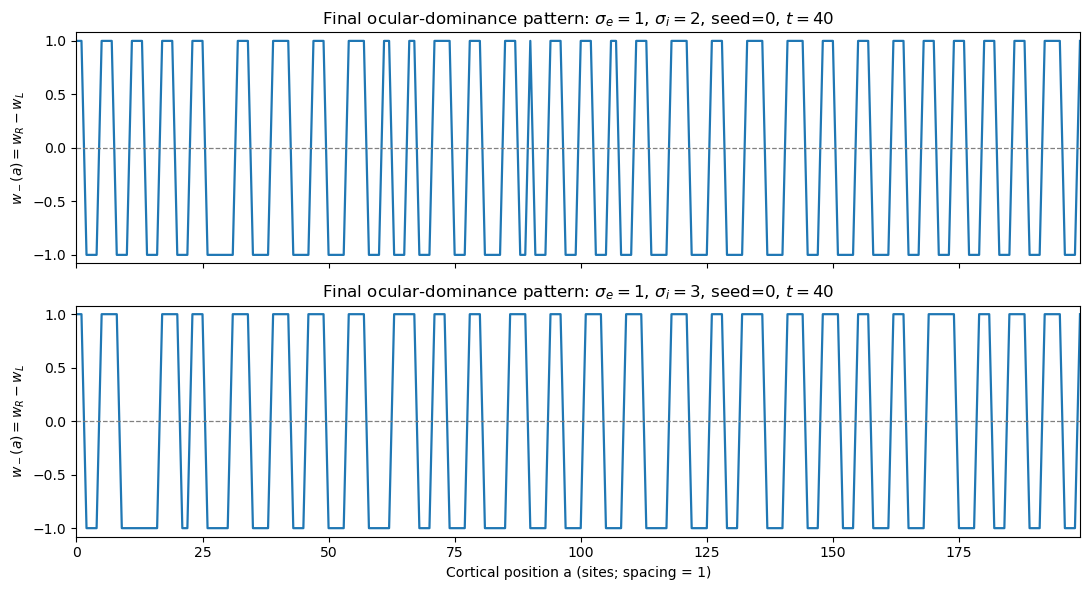

In [6]:
fig, axes = plt.subplots(2, 1, figsize=(11, 6), sharex=True, sharey=True)
for ax, sigma_i in zip(axes, sigma_i_values):
    w = example_patterns[sigma_i]
    x = np.arange(N)
    ax.plot(x, w, linewidth=1.6, label=fr"$\sigma_i={sigma_i:g}$")
    ax.axhline(0, color="gray", linestyle="--", linewidth=0.9)
    ax.set_ylabel(r"$w_-(a)=w_R-w_L$")
    ax.set_ylim(-1.08, 1.08)
    ax.set_xlim(0, N - 1)
    ax.set_title(fr"Final ocular-dominance pattern: $\sigma_e=1$, $\sigma_i={sigma_i:g}$, seed=0, $t=40$")
axes[-1].set_xlabel("Cortical position a (sites; spacing = 1)")
fig.tight_layout()
plt.show()

#### Stripe period across 20 seeds

In [7]:
def measure_period(w):
    # Compare every ring site to its preceding neighbor, including site 0 vs site N-1.
    sign_changes = np.count_nonzero(np.signbit(w) != np.signbit(np.roll(w, 1)))
    assert sign_changes % 2 == 0, "must be even number of sign changes"
    pairs = sign_changes // 2
    return pairs, (N / pairs if pairs > 0 else np.nan)

results = {}
for sigma_i in sigma_i_values:
    rows = []
    for seed in seeds:
        w = simulate(sigma_i, seed)
        pairs, period = measure_period(w)
        rows.append((seed, pairs, period))
    results[sigma_i] = np.asarray(rows, dtype=float)

for sigma_i, rows in results.items():
    periods = rows[:, 2]
    print(f"sigma_i={sigma_i:g}: mean period={periods.mean():.4f} sites, "
          f"sample SD={periods.std(ddof=1):.4f}, "
          f"range=[{periods.min():.4f}, {periods.max():.4f}]")

sigma_i=2: mean period=6.4397 sites, sample SD=0.2480, range=[6.0606, 7.1429]
sigma_i=3: mean period=8.1075 sites, sample SD=0.4953, range=[7.4074, 9.5238]


#### Theory vs discrete

In [8]:
def continuum_prediction(sigma_i):
    k_star = np.sqrt(4 * np.log(sigma_i / sigma_e)
                     / (sigma_i**2 - sigma_e**2))
    return k_star, 2 * np.pi / k_star

def discrete_prediction(sigma_i):
    K = make_kernel(N, sigma_e, sigma_i)
    eig = np.fft.rfft(K).real
    fastest_mode = int(np.argmax(eig[1:]) + 1)
    return fastest_mode, N / fastest_mode, eig[fastest_mode]

comparison = {}
print("sigma_i | continuum k* | continuum period | discrete mode | discrete period | measured mean ± SD")
print("-" * 100)
for sigma_i in sigma_i_values:
    k_star, period_cont = continuum_prediction(sigma_i)
    mode, period_disc, growth = discrete_prediction(sigma_i)
    values = results[sigma_i][:, 2]
    comparison[sigma_i] = (k_star, period_cont, mode, period_disc, values.mean(), values.std(ddof=1))
    print(f"{sigma_i:7.1f} | {k_star:12.4f} | {period_cont:16.4f} | "
          f"{mode:13d} | {period_disc:15.4f} | {values.mean():.4f} ± {values.std(ddof=1):.4f}")

sigma_i | continuum k* | continuum period | discrete mode | discrete period | measured mean ± SD
----------------------------------------------------------------------------------------------------
    2.0 |       0.9614 |           6.5358 |            31 |          6.4516 | 6.4397 ± 0.2480
    3.0 |       0.7412 |           8.4776 |            24 |          8.3333 | 8.1075 ± 0.4953


#### Periods across seeds

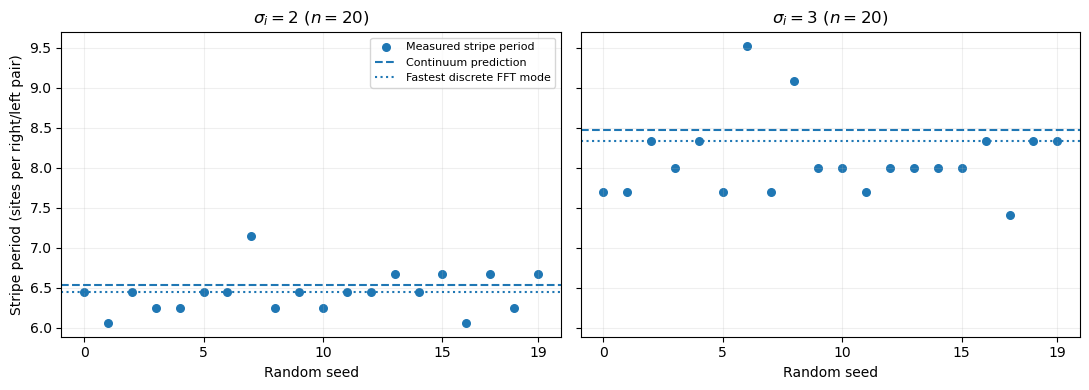

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, sigma_i in zip(axes, sigma_i_values):
    periods = results[sigma_i][:, 2]
    _, period_cont, _, period_disc, _, _ = comparison[sigma_i]
    ax.scatter(np.arange(n_seeds), periods, label="Measured stripe period", s=30)
    ax.axhline(period_cont, linewidth=1.5, linestyle="--", label="Continuum prediction")
    ax.axhline(period_disc, linewidth=1.5, linestyle=":", label="Fastest discrete FFT mode")
    ax.set_title(fr"$\sigma_i={sigma_i:g}$ ($n=20$)")
    ax.set_xlabel("Random seed")
    ax.set_xticks([0, 5, 10, 15, 19])
    ax.grid(alpha=0.2)
axes[0].set_ylabel("Stripe period (sites per right/left pair)")
axes[0].legend(fontsize=8)
fig.tight_layout()
plt.show()

The average measured stripe periods across 20 initial conditions were 6.440 +/- 0.248 sites for $\sigma_i=2$ and 8.107 +/- 0.495 sites for $\sigma_i=3$. These are close to the continuum predictions (6.536 and 8.478) and discrete FFT predictions (6.452 and 8.333). Increasing $\sigma_i$ increased the stripe spacing, consistent with the theoretical predictions.

### Q2d

#### Euler-Maruyama simulation

Simulate both populations with $w_s=w_c=(1+\lambda)/2$

In [5]:
mu = 0.2
sigma = 0.5
I0 = 5.0
dt_ddm = 0.002
n_trials = 10_000
thetas = np.arange(0.5, 4.01, 0.5)
lambda_values = [0.0, 0.2]

print(f"{n_trials} trials per threshold, dt={dt_ddm}, thresholds={thetas}")

10000 trials per threshold, dt=0.002, thresholds=[0.5 1.  1.5 2.  2.5 3.  3.5 4. ]


#### Simulate trials

In [6]:
def simulate_decisions(theta, lam, seed):
    rng = np.random.default_rng(seed)
    ws = wc = (1 + lam) / 2
    r1 = np.full(n_trials, I0)
    r2 = np.full(n_trials, I0)
    decision_time = np.zeros(n_trials)
    correct = np.zeros(n_trials, dtype=bool)
    active = np.ones(n_trials, dtype=bool)
    step = 0

    # Update only trials that have not yet reached a threshold.
    while np.any(active):
        ids = np.flatnonzero(active)
        a = r1[ids]
        b = r2[ids]
        z1 = rng.standard_normal(len(ids))
        z2 = rng.standard_normal(len(ids))
        next_r1 = a + (-a + ws*a - wc*b + I0 + mu/2) * dt_ddm + sigma*np.sqrt(dt_ddm)*z1
        next_r2 = b + (-b + ws*b - wc*a + I0 - mu/2) * dt_ddm + sigma*np.sqrt(dt_ddm)*z2
        r1[ids] = next_r1
        r2[ids] = next_r2
        step += 1
        reached = np.abs(next_r1 - next_r2) >= theta
        finished = ids[reached]
        decision_time[finished] = step * dt_ddm
        correct[finished] = (next_r1 - next_r2)[reached] >= theta
        active[finished] = False

    return correct.mean(), decision_time.mean()

ddm_results = {}
for lam in lambda_values:
    rows = []
    for j, theta in enumerate(thetas):
        accuracy, mean_time = simulate_decisions(theta, lam, seed=2026 + 100*j + int(lam*1000))
        rows.append((accuracy, mean_time))
    ddm_results[lam] = np.asarray(rows)
    print(f"lambda={lam:g}: accuracy={np.round(ddm_results[lam][:,0], 3)}")

lambda=0: accuracy=[0.611 0.705 0.766 0.84  0.877 0.919 0.941 0.962]
lambda=0.2: accuracy=[0.596 0.676 0.74  0.778 0.8   0.805 0.812 0.811]


#### Theory predictions

In [7]:
def integrator_accuracy(theta):
    return 1 / (1 + np.exp(-mu * theta / sigma**2))

def integrator_time(theta):
    return theta / mu * np.tanh(mu * theta / (2 * sigma**2))

def unstable_accuracy(theta, lam):
    # Completing the square in g(y) gives a normal CDF ratio.
    v = sigma / np.sqrt(lam)
    center = -mu / lam
    left = ndtr((-theta - center) / v)
    middle = ndtr((0 - center) / v)
    right = ndtr((theta - center) / v)
    return (middle - left) / (right - left)

def unstable_time(theta, lam, n_grid=2001):
    x = np.linspace(-theta, theta, n_grid)
    h = x[1] - x[0]
    drift = lam * x[1:-1] + mu
    lower = sigma**2/h**2 - drift/(2*h)
    diagonal = np.full(n_grid-2, -2*sigma**2/h**2)
    upper = sigma**2/h**2 + drift/(2*h)
    band = np.zeros((3, n_grid-2))
    band[0, 1:] = upper[:-1]
    band[1, :] = diagonal
    band[2, :-1] = lower[1:]
    interior = solve_banded((1, 1), band, -np.ones(n_grid-2))
    return interior[(n_grid-2)//2]

theory = {}
for lam in lambda_values:
    if lam == 0:
        acc = integrator_accuracy(thetas)
        times = integrator_time(thetas)
    else:
        acc = np.array([unstable_accuracy(theta, lam) for theta in thetas])
        times = np.array([unstable_time(theta, lam) for theta in thetas])
    theory[lam] = np.column_stack((acc, times))

print("lambda | theta | simulation accuracy | theory accuracy | simulation time | theory time")
for lam in lambda_values:
    for j, theta in enumerate(thetas):
        a, t = ddm_results[lam][j]
        pa, pt = theory[lam][j]
        print(f"{lam:5.1f} | {theta:5.1f} | {a:19.4f} | {pa:15.4f} | {t:15.3f} | {pt:11.3f}")

lambda | theta | simulation accuracy | theory accuracy | simulation time | theory time
  0.0 |   0.5 |              0.6114 |          0.5987 |           0.534 |       0.493
  0.0 |   1.0 |              0.7052 |          0.6900 |           1.968 |       1.900
  0.0 |   1.5 |              0.7663 |          0.7685 |           4.167 |       4.028
  0.0 |   2.0 |              0.8403 |          0.8320 |           6.776 |       6.640
  0.0 |   2.5 |              0.8771 |          0.8808 |           9.737 |       9.520
  0.0 |   3.0 |              0.9194 |          0.9168 |          12.576 |      12.505
  0.0 |   3.5 |              0.9413 |          0.9427 |          15.572 |      15.494
  0.0 |   4.0 |              0.9615 |          0.9608 |          18.634 |      18.433
  0.2 |   0.5 |              0.5960 |          0.5971 |           0.518 |       0.478
  0.2 |   1.0 |              0.6758 |          0.6789 |           1.732 |       1.684
  0.2 |   1.5 |              0.7401 |          0.7381

#### Accuracy and decision-time plots

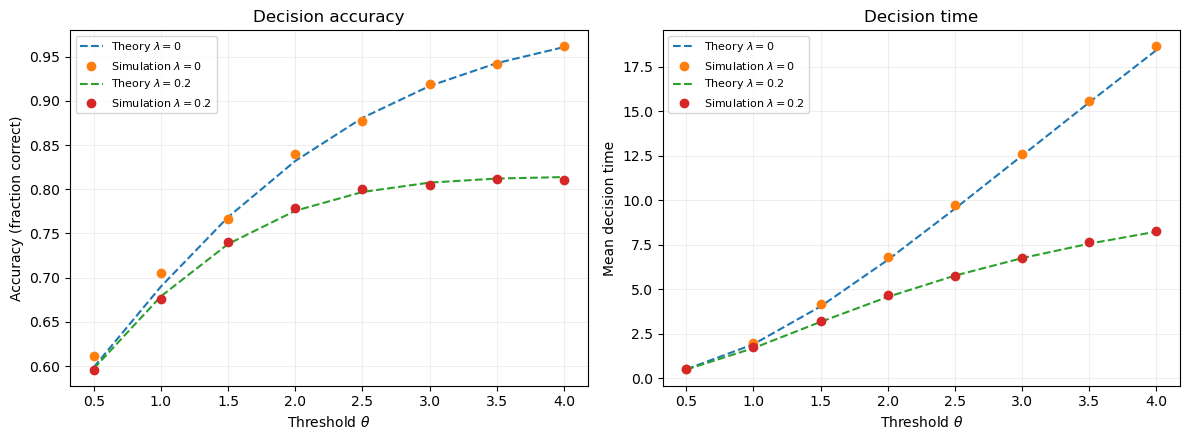

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for lam in lambda_values:
    sim = ddm_results[lam]
    pred = theory[lam]
    axes[0].plot(thetas, pred[:, 0], linestyle="--", label=fr"Theory $\lambda={lam:g}$")
    axes[0].plot(thetas, sim[:, 0], marker="o", linestyle="none", label=fr"Simulation $\lambda={lam:g}$")
    axes[1].plot(thetas, pred[:, 1], linestyle="--", label=fr"Theory $\lambda={lam:g}$")
    axes[1].plot(thetas, sim[:, 1], marker="o", linestyle="none", label=fr"Simulation $\lambda={lam:g}$")
axes[0].set_ylabel("Accuracy (fraction correct)")
axes[1].set_ylabel("Mean decision time")
for ax in axes:
    ax.set_xlabel(r"Threshold $\theta$")
    ax.set_xticks(thetas)
    ax.grid(alpha=0.2)
    ax.legend(fontsize=8)
axes[0].set_title("Decision accuracy")
axes[1].set_title("Decision time")
fig.tight_layout()
plt.show()

#### Matched-accuracy comparison

For $\lambda=0.2$ and $\theta=4$

In [9]:
lam = 0.2
theta_unstable = 4.0
accuracy_target = unstable_accuracy(theta_unstable, lam)
theta_match = (sigma**2 / mu) * np.log(accuracy_target / (1 - accuracy_target))
time_unstable = unstable_time(theta_unstable, lam)
time_integrator = integrator_time(theta_match)

sim_unstable_acc, sim_unstable_time = ddm_results[lam][-1]
# Simulate the perfect integrator at the matching (non-grid) threshold.
sim_match_acc, sim_match_time = simulate_decisions(theta_match, 0.0, seed=7342)

print(f"Unstable lambda=0.2, theta=4: theory accuracy={accuracy_target:.4f}, mean time={time_unstable:.3f}")
print(f"Perfect integrator matching theta={theta_match:.4f}: theory accuracy={integrator_accuracy(theta_match):.4f}, mean time={time_integrator:.3f}")
print(f"Simulated unstable: accuracy={sim_unstable_acc:.4f}, mean time={sim_unstable_time:.3f}")
print(f"Simulated integrator at theta={theta_match:.4f}: accuracy={sim_match_acc:.4f}, mean time={sim_match_time:.3f}")
print(f"Unstable/integrator theoretical mean-time ratio: {time_unstable/time_integrator:.3f}")

Unstable lambda=0.2, theta=4: theory accuracy=0.8138, mean time=8.231
Perfect integrator matching theta=1.8434: theory accuracy=0.8138, mean time=5.784
Simulated unstable: accuracy=0.8109, mean time=8.275
Simulated integrator at theta=1.8434: accuracy=0.8197, mean time=5.933
Unstable/integrator theoretical mean-time ratio: 1.423


Increasing the decision threshold generally increases decision time. Verses the perfect integrator, the unstable circuit approaches a maximum accuracy as the threshold grows. Positive feedback amplifies early fluxiations.

### Q3c

#### Hebbian network

Hopfield network of $N=500$ units. Compute $W=(XX^T)/N$ and set $W_{ii}=0$

In [10]:
from scipy.special import ndtr

N_h = 500
alphas = np.arange(0.02, 0.621, 0.04)
n_cues = 10
flip_fraction = 0.10
rng_h = np.random.default_rng(42)

def make_network(alpha):
    P = int(round(alpha * N_h))
    patterns = rng_h.choice([-1, 1], size=(N_h, P)).astype(np.float64)
    W = patterns @ patterns.T / N_h
    np.fill_diagonal(W, 0)
    return patterns, W

print(f"N = {N_h}, alpha values = {len(alphas)}, recall cues = {n_cues} per alpha")

N = 500, alpha values = 16, recall cues = 10 per alpha


#### Unstable stored bits

For each $\alpha$, evaluate the local fields of stored patterns.
A bit is unstable when $\xi_i^\mu h_i^\mu<0$.

In [11]:
unstable_fraction = []
recall_overlap = []
recall_sd = []
recall_sweeps = []

def recall_async(W, cue, max_sweeps=200):
    s = cue.copy()
    h = W @ s
    for sweep in range(1, max_sweeps + 1):
        changed = 0
        for i in rng_h.permutation(len(s)):
            new_bit = 1.0 if h[i] >= 0 else -1.0  # sgn(0) = +1
            if new_bit != s[i]:
                delta = new_bit - s[i]
                s[i] = new_bit
                h += W[:, i] * delta  # update local fields after a flip
                changed += 1
        if changed == 0:
            return s, sweep, True
    return s, max_sweeps, False

for alpha in alphas:
    patterns, W = make_network(alpha)
    fields = W @ patterns
    unstable_fraction.append(np.mean(patterns * fields < 0))

    overlaps = []
    sweeps = []
    for _ in range(n_cues):
        index = rng_h.integers(patterns.shape[1])
        target = patterns[:, index]
        cue = target.copy()
        flipped = rng_h.choice(N_h, size=int(flip_fraction * N_h), replace=False)
        cue[flipped] *= -1
        recovered, n_sweeps, converged = recall_async(W, cue)
        if not converged:
            print(f"Warning: alpha={alpha:.2f}, cue did not converge")
        overlaps.append(np.dot(target, recovered) / N_h)
        sweeps.append(n_sweeps)

    recall_overlap.append(np.mean(overlaps))
    recall_sd.append(np.std(overlaps, ddof=1))
    recall_sweeps.append(np.mean(sweeps))

unstable_fraction = np.array(unstable_fraction)
recall_overlap = np.array(recall_overlap)
recall_sd = np.array(recall_sd)
predicted_unstable = ndtr(-1 / np.sqrt(alphas))

print("alpha   unstable   predicted    mean recall m")
for a, measured, predicted, m in zip(alphas, unstable_fraction, predicted_unstable, recall_overlap):
    print(f"{a:5.2f}   {measured:8.4f}   {predicted:8.4f}      {m:8.4f}")

alpha   unstable   predicted    mean recall m
 0.02     0.0000     0.0000        1.0000
 0.06     0.0000     0.0000        1.0000
 0.10     0.0005     0.0008        0.9924
 0.14     0.0026     0.0038        0.9672
 0.18     0.0095     0.0092        0.4452
 0.22     0.0156     0.0165        0.3528
 0.26     0.0259     0.0249        0.4188
 0.30     0.0327     0.0339        0.3232
 0.34     0.0433     0.0432        0.3772
 0.38     0.0523     0.0524        0.3324
 0.42     0.0608     0.0614        0.2976
 0.46     0.0715     0.0702        0.2976
 0.50     0.0795     0.0786        0.2560
 0.54     0.0876     0.0868        0.2684
 0.58     0.0936     0.0946        0.3068
 0.62     0.1009     0.1020        0.3032


#### Plot unstable bits and recall overlap

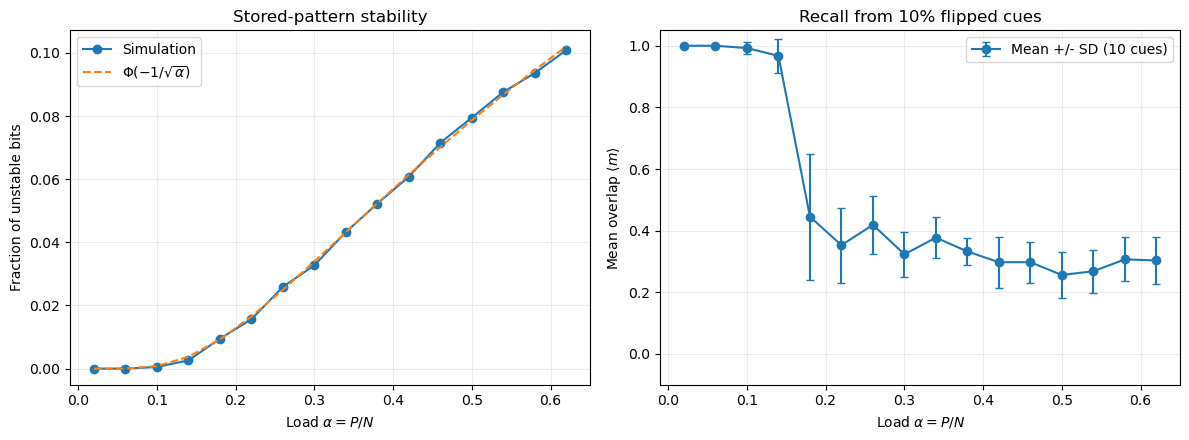

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].plot(alphas, unstable_fraction, "o-", label="Simulation")
axes[0].plot(alphas, predicted_unstable, "--", label=r"$\Phi(-1/\sqrt{\alpha})$")
axes[0].set(xlabel=r"Load $\alpha=P/N$", ylabel="Fraction of unstable bits", title="Stored-pattern stability")
axes[0].legend()
axes[0].grid(alpha=0.25)

axes[1].errorbar(alphas, recall_overlap, yerr=recall_sd, fmt="o-", capsize=3, label="Mean +/- SD (10 cues)")
axes[1].set(xlabel=r"Load $\alpha=P/N$", ylabel=r"Mean overlap $\langle m\rangle$", title="Recall from 10% flipped cues")
axes[1].set_ylim(-0.1, 1.05)
axes[1].legend()
axes[1].grid(alpha=0.25)
plt.tight_layout()
plt.show()

Recall breaks down  between $\alpha=0.14$ and $\alpha=0.18$, where the mean overlap drops sharply from approximately 0.97 to 0.45.